# F03.01 · Datos de la red: preparar lo que la red va a ver

> 🧭 **En 30 segundos**
> - **Para qué:** antes de construir la red neuronal (F03.02) hay que dejarle los datos **listos para comer**: qué ventanas son para estudiar y cuáles para el examen, leídas del disco, en la misma escala y repartidas en grupos de 64.
> - **Entra:** las listas de ventanas de **F02.04** y **F02.05** y la señal guardada en **F02.02** → **Sale:** unos ficheros grandes llamados **paquetes**, listos para la red.
> - **Idea clave:** aquí **no se entrena nada**. Es la "cocina": si los ingredientes llegan mal preparados, da igual lo buena que sea la receta.

> 📍 **Dónde estamos: Fase 3 · notebook 1 (F03.01).** La Fase 2 terminó con **listas** (qué ventana es, de qué paciente, dónde está su señal), pero sin tocar la señal para la red. Este notebook es el puente entre esas listas y la red.

> 🔄 **Es dinámico.** Lee lo que dejaron F02.03, F02.04 y F02.05, y todas las cifras y conclusiones salen de los datos al ejecutarlo.

| Fase del TFM | | Estado |
|---|---|---|
| Fase 1 | Exploración de datos | ✅ terminada |
| Fase 2 | Preprocesado y ventanas | ✅ terminada |
| **Fase 3** | **Modelo de predicción (⏳ preictal frente a 💤 interictal)** | 👉 **en curso** (la fase de este notebook) |
| Fase 4 | Clasificación de tipos de crisis | pendiente |
| Fase 5 | Explicabilidad (XAI) | pendiente |
| Fase 6 | Memoria | pendiente |
| Fase 7 | Revisión y defensa | pendiente |

> 🏷️ **Cómo se nombran los notebooks.** `F02.04` = Fase 2, notebook 04 (`fase_02/04_particiones_y_balanceo.ipynb`). Este es el `F03.01`.

## El recorrido de este notebook

![El recorrido del notebook F03.01](img/mapa_notebook_01.png)

👀 **Qué enseña.** Los seis pasos, en orden. Cada caja es una sección (§). Los dos en rojo son los más importantes: **repartir** bien las ventanas (si un paciente se cuela en el examen, la nota no vale) y **servir lotes**, que es lo que usará la red.

## Antes de empezar: qué recibe la red

![Qué recibe la red y qué devuelve](img/que_aprende_la_red.png)

👀 **Qué enseña.** La red recibe **una ventana**: 4 segundos de EEG de los 22 canales, es decir, una tabla de 22 × 1.024 números. Devuelve **un número entre 0 y 1**: lo probable que es que esa ventana sea ⏳ preictal (que se acerca una crisis). Para aprender a hacerlo necesita **miles de ventanas con su respuesta correcta**. Este notebook prepara justo eso.

### 📖 Diccionario rápido

| Término | Qué significa, en sencillo |
|---|---|
| **Ventana** | Un trozo de 4 s de EEG (las crea F02.03). Es lo que ve la red de una vez |
| **Etiqueta** | La respuesta correcta de cada ventana: **1** = ⏳ preictal (antes de una crisis), **0** = 💤 interictal (lejos de cualquier crisis) |
| **µV (microvoltios)** | La unidad en la que mide el EEG |
| **Partición: train / dev / eval** | Cómo viene repartido TUSZ por pacientes: 🔵 para estudiar, 🟡 para examen de prueba, 🟢 para el examen final |
| **Vista** | El grupo de ventanas que se usa para una cosa concreta (estudiar, examen de prueba, examen final, cada control). Ver §3 |
| **Control** | El examen final, pero sin las "pistas tramposas" que encontró F02.05. Si la nota se mantiene, la red no hacía trampa |
| **Desbalance** | Que haya muchas más 💤 que ⏳. En la vida real es así; para estudiar se equilibra mitad y mitad (F02.04) |
| **Paquete** | Un fichero grande con todas las ventanas de una partición, juntas, para leerlas rápido. Ver §4 |
| **Normalizar** | Poner todas las ventanas en la misma escala, para que la red mire la forma de la onda y no su tamaño. Ver §6 |
| **Artefacto** | Un trozo de señal que no viene del cerebro: un movimiento, un parpadeo, un electrodo que se suelta. Suele ser un pico enorme |
| **Aumento de datos** | Crear ejemplos nuevos y creíbles a partir de los que hay (aquí, reflejando izquierda ↔ derecha). Ver §7 |
| **Lote** | Un grupo de 64 ventanas que la red ve de golpe. Ver §8 |
| **Época** | Una vuelta completa por todas las ventanas de estudio. Se dan decenas de vueltas |
| **PyTorch** | La librería de Python con la que se construyen y entrenan las redes |
| **Tensor** | La "tabla de números" de PyTorch (como un array de numpy, pero que puede ir a la GPU) |
| **GPU / CUDA** | La tarjeta gráfica. Hace miles de cuentas a la vez y entrena mucho más rápido que el procesador (CPU). CUDA es lo que permite a PyTorch usar una tarjeta NVIDIA |
| **Dataset / DataLoader** | Las dos piezas de PyTorch que sirven los datos: el almacén y el repartidor. Ver §8 |
| **Semilla** | Un número que fija el azar: con la misma semilla, el "azar" sale siempre igual y el resultado se puede repetir |
| **float16 / float32** | Cuántos decimales se guardan de cada número. float16 ocupa la mitad (para guardar); float32 es más preciso (para la red) |

## 0. El parámetro: qué conjunto se prepara

F02.04 preparó un **conjunto** de ventanas por cada modelo que se quiere probar (el general, uno por umbral de aviso, uno por grupo de crisis...). Aquí se elige cuál preparar. **`general`** es el modelo principal: empezamos por él.

*(La celda lleva la etiqueta `parameters` para poder lanzarla con papermill cambiando solo este valor.)*

In [1]:
CONJUNTO = 'general'

## 1. Librerías y tarjeta gráfica

> 🎯 **Qué hacemos:** comprobar que están instaladas las librerías (las que falten se instalan solas) y ver **dónde** se harán las cuentas de la red.
>
> 🤔 **Por qué:** **PyTorch** es nueva en el TFM. Con una tarjeta **NVIDIA**, se instala la versión con **CUDA** para entrenar en la **GPU**; si PyTorch estaba instalado sin CUDA, lo cambia solo (después hay que reiniciar el kernel).

In [2]:
# Requisitos: se comprueba (e instala si falta) lo que necesita el notebook ANTES de importar nada más
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))
from tfm_comun.entorno.requisitos import comprobar_requisitos, REQUISITOS_FASE_03_DATOS
disponibles = comprobar_requisitos(REQUISITOS_FASE_03_DATOS)

,estado,versión,para qué
librería,,,
numpy,✅,2.5.4,cálculo con matrices
pandas,✅,3.0.6,tablas
matplotlib,✅,3.11.2,figuras
tqdm,✅,4.70.1,barra de progreso al crear los paquetes
torch,✅,2.15.0+cu132,"red neuronal: Dataset, DataLoader y tensores (PyTorch)"


Todo lo necesario está instalado.


In [3]:
# Recarga automática: si cambia un módulo de tfm_comun, se vuelve a cargar solo (sin reiniciar el kernel)
%load_ext autoreload
%autoreload 2

# Vuelve a leer tfm_comun del disco cada vez que se ejecuta esta celda (por si ha cambiado), sin reiniciar el kernel
for modulo in [m for m in list(sys.modules) if m == 'tfm_comun' or m.startswith('tfm_comun.')]:
    del sys.modules[modulo]

import json
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch.utils.data import ConcatDataset
from tqdm.auto import tqdm
from IPython.display import display, Markdown

from tfm_comun.entorno.rutas import RUTA_OUTPUTS_FASE_02, RUTA_OUTPUTS_FASE_03, RUTA_SENALES, carpeta_resultados
from tfm_comun.entorno.versiones import mostrar_versiones
from tfm_comun.entorno.dispositivo import elegir_dispositivo
from tfm_comun.prediccion.balanceo import SEMILLA
from tfm_comun.prediccion.vistas import (DESCRIPCION_VISTAS, leer_conjunto, leer_controles, armar_vistas,
                                          tabla_vistas, indice_por_particion, tiene_validacion_cruzada)
from tfm_comun.red.paquetes import rutas_paquete, paquete_al_dia, crear_paquete, cargar_paquete
from tfm_comun.red.datos import VentanasEEG, PrepararLote, crear_cargador
from tfm_comun.red.aumento import ORIGEN_ESPEJO, SIGNO_ESPEJO, reflejar_hemisferios
from tfm_comun.red.reproducibilidad import fijar_semillas
from tfm_comun.senal.senales import cargar_tramo
from tfm_comun.senal.normalizacion import NORMALIZACIONES
from tfm_comun.senal.montaje import CADENAS_TCP, CANALES_TCP, CANALES_FIGURAS
from tfm_comun.visual.iconos import con_icono, tabla_con_iconos
from tfm_comun.visual.colores import COLORES_PERIODO
from tfm_comun.visual.numeros import numero_legible
from tfm_comun.visual.tablas import con_separadores, mostrar_destacado
from tfm_comun.visual.ficheros import mostrar_fichero
from tfm_comun.visual.tipografia import ESTILO_TIMES

versiones_usadas = mostrar_versiones(np, pd, matplotlib, torch)

Python      3.14.0
numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2
torch       2.15.0+cu132


In [4]:
# Dónde se harán las cuentas de la red (aquí no se entrena: es para saberlo desde el principio)
# Lo que se quiere ver: 'cuda (GPU NVIDIA)' y el nombre de la tarjeta
dispositivo, ficha_dispositivo = elegir_dispositivo()
display(pd.DataFrame({'valor': ficha_dispositivo}).rename_axis('dispositivo').style.set_properties(**{'text-align': 'left'}))

,valor
dispositivo,
dispositivo,cuda (GPU NVIDIA)
nombre,NVIDIA GeForce RTX 3060
memoria (GB),12.900000
aviso,


✅ **Qué deberías ver:** en la tabla de librerías, todas con ✅ y `torch` con `+cu…` en la versión (no `+cpu`); en la del dispositivo, **`cuda (GPU NVIDIA)`** y el nombre de tu tarjeta.

## 2. Configuración

> 🎯 **Qué hacemos:** fijar los "botones" del notebook y leer lo que dejaron los notebooks de la Fase 2.
>
> 🤔 **Por qué:** no hay que copiar a mano ninguna cifra: el tamaño de la ventana sale de F02.03, los conjuntos de F02.04 y las medidas contra trampas de F02.05.

| Parámetro | Valor | Qué controla |
|---|---|---|
| `NORMALIZACION` | `'robusta'` | Cómo se pone cada ventana en la misma escala: `'robusta'` (aguanta bien los artefactos) o `'zscore'` (la clásica). La §6 explica la diferencia con imágenes y las compara con los datos |
| `RECORTE` | 20 | Tras normalizar, lo que pase de ±20 se deja en ±20: un artefacto no se queda en valores enormes que desestabilicen a la red. La §6 mide a cuántas ventanas afecta |
| `REFLEJO` | 0,5 | Al estudiar, la mitad de las ventanas (al azar) se reflejan izquierda ↔ derecha para tener más variedad (§7). 0 = no reflejar |
| `TAMANO_LOTE` | 64 | Ventanas que ve la red de golpe (§8). Es el valor más habitual en los trabajos con TUSZ de la síntesis del estado del arte (Hu 2024, Albaqami 2023, Fan 2024) |
| `N_TRABAJADORES` | 0 | Ayudantes que preparan lotes en paralelo mientras la red estudia. 0 = sin ayudantes (lo más seguro en Windows). La §8 dice si hacen falta |
| `SPLITS_CONTROL` | `['eval']` | Los controles de F02.05 se preparan solo para el examen final (🟢 eval) |
| `N_COMPROBAR` | 300 | Ventanas al azar que se comparan, número a número, con la señal original (§5) |
| `N_MUESTRA` | 2.000 | Ventanas al azar con las que se comparan las dos normalizaciones (§6) |
| `N_LOTES_VELOCIDAD` | 50 | Lotes con los que se mide la velocidad (§8) |

La **semilla** es la de todo el TFM (`SEMILLA = 42`): el azar sale siempre igual.

In [5]:
NORMALIZACION = 'robusta'
RECORTE = 20
REFLEJO = 0.5
TAMANO_LOTE = 64
N_TRABAJADORES = 0
SPLITS_CONTROL = ['eval']
N_COMPROBAR = 300
N_MUESTRA = 2000
N_LOTES_VELOCIDAD = 50

In [6]:
RUTA_RESULTADOS, RUTA_FIGURAS = carpeta_resultados('fase_03/01_datos_red')
fijar_semillas(SEMILLA)

# Lo que dejó la Fase 2: ventanas (F02.03), conjuntos (F02.04) y medidas contra trampas (F02.05)
def leer_json(ruta, notebook):
    assert ruta.exists(), f'No encuentro {ruta}. Ejecuta antes F02.{notebook[:2]} (fase_02/{notebook}.ipynb).'
    return json.loads(ruta.read_text(encoding='utf-8'))
config_03 = leer_json(RUTA_OUTPUTS_FASE_02 / '03_ventanas' / 'configuracion.json', '03_ventanas')
config_04 = leer_json(RUTA_OUTPUTS_FASE_02 / '04_particiones_y_balanceo' / 'configuracion.json', '04_particiones_y_balanceo')
config_05 = leer_json(RUTA_OUTPUTS_FASE_02 / '05_auditoria_atajos' / 'configuracion.json', '05_auditoria_atajos')
RUTA_MEDIDAS = RUTA_OUTPUTS_FASE_02 / '05_auditoria_atajos' / 'medidas_fase_03.csv'
assert RUTA_MEDIDAS.exists(), f'No encuentro {RUTA_MEDIDAS}. Ejecuta antes F02.05 (fase_02/05_auditoria_atajos.ipynb).'
medidas = pd.read_csv(RUTA_MEDIDAS)

MUESTRAS = int(config_03['muestras_por_ventana'])
VENTANA_S = config_03['ventana_s']
N_CANALES = len(CANALES_TCP)
modo_prueba = bool(config_03['modo_prueba'] or config_04['modo_prueba'])
assert NORMALIZACION in NORMALIZACIONES, f'NORMALIZACION tiene que ser una de {list(NORMALIZACIONES)}'

def decimal(valor, cifras=1):   # número con coma decimal y cifras fijas, para los textos: 2.35 -> '2,4'
    return f'{valor:.{cifras}f}'.replace('.', ',')

print(f'Conjunto: {CONJUNTO} · ventanas de {VENTANA_S} s = {N_CANALES} canales × {numero_legible(MUESTRAS)} muestras'
      + ('  ·  ⚠️ MODO PRUEBA: la Fase 2 se ejecutó con datos incompletos' if modo_prueba else ''))
auditado = CONJUNTO == config_05['conjunto']
display(Markdown(f'**Lo que pide F02.05 (auditoría de trampas) para la Fase 3** (revisó el conjunto `{config_05["conjunto"]}`'
                 + ('' if auditado else f'; `{CONJUNTO}` no se revisó: las medidas se aplican igual, pero no tiene controles') + ')'))
display(medidas.set_index('atajo').style.set_properties(**{'text-align': 'left'}).format(precision=2))

Conjunto: general · ventanas de 4 s = 22 canales × 1.024 muestras


**Lo que pide F02.05 (auditoría de trampas) para la Fase 3** (revisó el conjunto `general`)

,semáforo,fuerza que decide,medida,obligatoria
atajo,,,,
canales a 0 (H1),🟢 no separa,0.52,Ninguna: no separa. Se puede seguir con 22 canales,False
equipo: montaje y Hz (H2),🟢 no separa,0.53,Ninguna: no separa,False
nivel de señal (H3),🟡 separa un poco,0.56,Mantener la normalización por ventana y canal (normalizacion.py); no usar normalización global,True
posición en el fichero (H4),🔴 separa mucho,0.75,Evaluar la red también en conjuntos_control/general_emparejado_posicion.csv y comparar con la nota normal,True
tipo de fichero (H5),🔴 separa mucho,0.93,Medir la red también en conjuntos_control/general_misma_sesion.csv (y en su variante estricta) y comparar con la nota normal,True
techo del atajo (sección 10),🟡 separa un poco,0.61,"Dar la nota de la red en el conjunto normal y en los controles; el techo (0.61 en eval) es lo máximo que la posición podría explicar, no una nota a superar",True
inicio del fichero (03),🟢 corregido,nan,Hecho: 03 descarta las ventanas de los primeros segundos de cada fichero,False
equilibrado por paciente (04),🟢 corregido,nan,Hecho: 04 deja cada paciente de train exactamente mitad y mitad,False


👀 **Cómo leer la tabla.** En F02.05 se buscaron **atajos**: pistas que no son el EEG antes de la crisis (en qué minuto del fichero está la ventana, de qué tipo de fichero sale...) y con las que la red podría "aprobar haciendo trampa". Cada fila es una pista, con su semáforo. Las que tienen `obligatoria = True` afectan a este notebook:

- **nivel de señal** → normalizar cada ventana con sus propios valores (§6).
- **posición en el fichero** y **tipo de fichero** → preparar los **conjuntos de control** para el examen final (§3).

## 3. Repartir: qué ventanas son para estudiar y cuáles para el examen

> 🎯 **Qué hacemos:** separar las ventanas en grupos (**vistas**) según para qué se usan.
>
> 🤔 **Por qué:** una red, como un estudiante, puede **memorizar** los ejercicios en vez de **aprender**. Para saber si ha aprendido de verdad, hay que examinarla con ventanas que **nunca** ha visto, de pacientes que **nunca** ha visto.

![Tres grupos de ventanas, como un estudiante](img/tres_grupos.png)

👀 **Qué enseña.** Los tres grupos y para qué sirve cada uno. Los **controles** son el mismo examen final quitando las pistas tramposas de F02.05: el de **posición** usa 💤 de los mismos minutos del fichero que las ⏳; el de **misma sesión** usa 💤 del mismo día que la crisis (en su versión **estricta**, solo de antes de la primera crisis del día).

In [7]:
conjunto = leer_conjunto(CONJUNTO)
controles = leer_controles(CONJUNTO)
vistas = armar_vistas(conjunto, controles, SPLITS_CONTROL)
resumen_vistas = tabla_vistas(vistas)
display(con_separadores(resumen_vistas, decimales=2))

,partición,para qué,pacientes,crisis,⏳ preictal,💤 interictal,💤 por cada ⏳,ventanas
vista,,,,,,,,
entrenamiento,train,Entrenar la red (equilibrado: mitad y mitad en cada paciente),84,247,18.417,18.417,"1,00",36.834
validacion,dev,"Elegir época, hiperparámetros y umbral (desbalance real)",36,133,11.190,47.281,"4,23",58.471
evaluacion,eval,Nota final (desbalance real). Solo se mira al final,30,98,8.375,40.211,"4,80",48.586
control_posicion,eval,Control H4: 💤 de los mismos minutos del fichero que las ⏳,27,98,8.375,6.012,"0,72",14.387
control_misma_sesion,eval,Control H5: 💤 de ficheros sin crisis de la misma sesión,28,98,8.375,17.773,"2,12",26.148
control_misma_sesion_estricta,eval,Control H5 estricto: solo 💤 de ficheros anteriores a la 1.ª crisis,27,98,8.375,6.049,"0,72",14.424


👀 **Cómo leer la tabla.** Una fila por grupo (vista):

- **pacientes / crisis**: de cuántos pacientes y crisis distintos salen sus ventanas.
- **⏳ preictal / 💤 interictal**: cuántas ventanas hay de cada clase.
- **💤 por cada ⏳**: el **desbalance**. En *entrenamiento* tiene que salir **1** (mitad y mitad, como dejó F02.04). En *validacion* y *evaluacion* sale mucho más alto, como en la vida real: así las notas serán honestas.

Los controles tienen **las mismas ⏳** que *evaluacion*; solo cambian sus 💤.

✅ **Qué deberías ver:** *entrenamiento* con 💤 por cada ⏳ = 1; *validacion* y *evaluacion* bastante por encima de 1.

In [8]:
# Comprobaciones antes de seguir: si alguna falla, todo lo que viene después no valdría
# La más importante: ningún paciente de estudio puede aparecer en los exámenes
vistas_de_medida = [v for v in vistas if v != 'entrenamiento' and v != 'validacion_cruzada']
pacientes_entrena = set(vistas['entrenamiento'].patient)
pacientes_fuera = set().union(*(set(vistas[v].patient) for v in vistas_de_medida))
etiqueta_mal = sum(int(((t.clase == 'preictal').astype(int) != t.etiqueta).sum()) for t in vistas.values())
obligatorias = medidas[medidas.obligatoria]
# Los controles solo se exigen para el conjunto que revisó F02.05 (para los demás, F02.05 no los creó)
falta_control = [a for a, vista in [('posición en el fichero (H4)', 'control_posicion'), ('tipo de fichero (H5)', 'control_misma_sesion')]
                 if auditado and a in set(obligatorias.atajo) and vista not in vistas]
comprobaciones = {
    'pacientes de entrenamiento que están en las vistas de medida': len(pacientes_entrena & pacientes_fuera),
    'ventanas con la etiqueta distinta de su clase (1 = ⏳ preictal)': etiqueta_mal,
    'controles obligatorios de F02.05 que no se han encontrado': len(falta_control),
    'vistas vacías': sum(len(t) == 0 for t in vistas.values()),
}
for texto, n in comprobaciones.items():
    print(f'{"✅" if n == 0 else "🔴"} {texto} (debe ser 0): {n}')
porcentaje_pre = 100 * (vistas['entrenamiento'].clase == 'preictal').mean()
if not auditado:
    print(f'🟡 {CONJUNTO} no lo revisó F02.05: no tiene conjuntos de control (la nota final no se podrá contrastar con ellos)')
print(f'{"✅" if abs(porcentaje_pre - 50) < 1 else "🟡"} ⏳ preictal en entrenamiento: {decimal(porcentaje_pre)} % (equilibrado = 50 %)')
assert all(n == 0 for n in comprobaciones.values()), f'🔴 Alguna comprobación ha fallado. Controles que faltan: {falta_control}'

✅ pacientes de entrenamiento que están en las vistas de medida (debe ser 0): 0
✅ ventanas con la etiqueta distinta de su clase (1 = ⏳ preictal) (debe ser 0): 0
✅ controles obligatorios de F02.05 que no se han encontrado (debe ser 0): 0
✅ vistas vacías (debe ser 0): 0
✅ ⏳ preictal en entrenamiento: 50,0 % (equilibrado = 50 %)


## 4. Empaquetar: leer la señal del disco una sola vez

> 🎯 **Qué hacemos:** copiar la señal de cada ventana desde los miles de ficheros de F02.02 a **un fichero por partición** (`train.npy`, `dev.npy`, `eval.npy`): el **paquete**.
>
> 🤔 **Por qué:** la red ve cada ventana **muchas veces** (una por época). Buscarla cada vez entre miles de ficheros sería muy lento.

![Lotes y épocas: cómo estudia la red](img/lotes_y_epocas.png)

👀 **Qué enseña.** Cómo estudia una red: baraja las ventanas, las ve de 64 en 64 (**lotes**) y, tras verlas todas (**una época**), vuelve a empezar, decenas de veces. Por eso hay que poder leerlas rápido.

![Por qué un paquete](img/paquete.png)

👀 **Qué enseña.** A la izquierda, cómo está la señal ahora (un fichero por tramo, miles). A la derecha, el paquete: las ventanas seguidas en un solo fichero. Se crea **una vez**; si ya existe con exactamente las mismas ventanas, se reutiliza y esta sección tarda segundos.

> 💡 Una ventana puede estar en varios grupos (una ⏳ de eval está en *evaluacion* y en los tres controles), pero en el paquete se guarda **una sola vez**. Su fila del índice dice a qué grupos pertenece (columnas `en_entrenamiento`, `en_evaluacion`...).

In [9]:
indices = indice_por_particion(vistas)
filas_paquetes = {}
for split, indice in indices.items():
    inicio = time.time()
    if paquete_al_dia(CONJUNTO, split, indice, N_CANALES, MUESTRAS):
        estado, info = 'ya estaba al día', {'ventanas': len(indice), 'ficheros .npy leídos': 0}
    else:
        estado = 'creado'
        info = crear_paquete(CONJUNTO, split, indice, N_CANALES, MUESTRAS, progreso=lambda it, total: tqdm(it, total=total, desc=f'{split}: ficheros de F02.02 leídos'))
    ruta_npy, _ = rutas_paquete(CONJUNTO, split)
    filas_paquetes[split] = {'estado': estado, 'ventanas': len(indice), 'pacientes': indice.patient.nunique(),
                             'ficheros de F02.02 de los que sale': indice.ruta.nunique(), 'GB': ruta_npy.stat().st_size / 1e9,
                             'segundos': time.time() - inicio}
tabla_paquetes = pd.DataFrame(filas_paquetes).T
tabla_paquetes.index.name = 'split'
display(con_separadores(tabla_con_iconos(tabla_paquetes), decimales=2))

,estado,ventanas,pacientes,ficheros de F02.02 de los que sale,GB,segundos
split,,,,,,
🔵 train,ya estaba al día,36.834,84,1.489,"1,66","0,09"
🟡 dev,ya estaba al día,58.471,36,1.576,"2,63","0,13"
🟢 eval,ya estaba al día,48.586,30,639,"2,19","0,10"


👀 **Cómo leer la tabla.** Una fila por paquete (partición): si se ha **creado** ahora o **ya estaba al día**, cuántas ventanas guarda, de cuántos pacientes, de cuántos ficheros de F02.02 se han sacado, cuánto ocupa (GB) y cuánto ha tardado.

✅ **Qué deberías ver:** la primera vez, *creado* y unos minutos; las siguientes, *ya estaba al día* y segundos.

In [10]:
# Qué hay dentro de un paquete: el índice (.csv, una fila por ventana) y la señal (.npy), leídos otra vez del disco
for split in indices:
    ruta_npy, ruta_csv = rutas_paquete(CONJUNTO, split)
    mostrar_fichero(ruta_csv, f'una fila por ventana del paquete {split}, en el mismo orden que el .npy: id, paciente, clase, '
                    'etiqueta (1 = ⏳ preictal, 0 = 💤 interictal), de qué fichero de F02.02 salió (ruta + muestra_inicio) y a qué grupos pertenece (en_...)',
                    filas=3)

split_ejemplo = next(iter(indices))
matriz, indice_ejemplo = cargar_paquete(CONJUNTO, split_ejemplo)
ruta_npy, _ = rutas_paquete(CONJUNTO, split_ejemplo)
primera = pd.DataFrame(np.asarray(matriz[0, :5, :6], dtype=np.float32), index=CANALES_TCP[:5],
                       columns=[f'muestra {i}' for i in range(6)])
primera.index.name = 'canal'
display(Markdown(f'💾 **`{ruta_npy.name}`** · {numero_legible(round(ruta_npy.stat().st_size / 1e9, 2))} GB · '
                 f'{" × ".join(numero_legible(n) for n in matriz.shape)} ({matriz.dtype})  \n'
                 f'*Qué guarda:* la señal de cada ventana en µV, sin normalizar: ventanas × canales × muestras. '
                 f'*Abajo:* los 5 primeros canales y 6 primeras muestras de la ventana 0 (`{indice_ejemplo.id_ventana[0]}`).'))
display(con_separadores(primera, decimales=2))

💾 **Guardado `train_indice.csv`** · 8,1 MB · 36.834 filas × 18 columnas  
*Qué guarda:* una fila por ventana del paquete train, en el mismo orden que el .npy: id, paciente, clase, etiqueta (1 = ⏳ preictal, 0 = 💤 interictal), de qué fichero de F02.02 salió (ruta + muestra_inicio) y a qué grupos pertenece (en_...). *Abajo:* las 3 primeras filas.

,id_ventana,split,patient,file,clase,etiqueta,tipo,grupo,crisis_id,ruta,muestra_inicio,segundos_hasta_crisis,en_entrenamiento,en_validacion,en_evaluacion,en_control_posicion,en_control_misma_sesion,en_control_misma_sesion_estricta
0,aaaaaacz_s001_t001_interictal_000000000_000005120,🔵 train,aaaaaacz,aaaaaacz_s001_t001,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaacz_s001_t001_interictal...,5120,NaN,True,False,False,False,False,False
1,aaaaaacz_s001_t001_interictal_000000000_000010240,🔵 train,aaaaaacz,aaaaaacz_s001_t001,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaacz_s001_t001_interictal...,10240,NaN,True,False,False,False,False,False
2,aaaaaacz_s001_t001_interictal_000000000_000013312,🔵 train,aaaaaacz,aaaaaacz_s001_t001,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaacz_s001_t001_interictal...,13312,NaN,True,False,False,False,False,False


💾 **Guardado `dev_indice.csv`** · 12,1 MB · 58.471 filas × 18 columnas  
*Qué guarda:* una fila por ventana del paquete dev, en el mismo orden que el .npy: id, paciente, clase, etiqueta (1 = ⏳ preictal, 0 = 💤 interictal), de qué fichero de F02.02 salió (ruta + muestra_inicio) y a qué grupos pertenece (en_...). *Abajo:* las 3 primeras filas.

,id_ventana,split,patient,file,clase,etiqueta,tipo,grupo,crisis_id,ruta,muestra_inicio,segundos_hasta_crisis,en_entrenamiento,en_validacion,en_evaluacion,en_control_posicion,en_control_misma_sesion,en_control_misma_sesion_estricta
0,aaaaaajy_s003_t004_interictal_000000000_000003072,🟡 dev,aaaaaajy,aaaaaajy_s003_t004,💤 interictal,0,nan,nan,NaN,dev/interictal/aaaaaajy_s003_t004_interictal_0...,3072,NaN,False,True,False,False,False,False
1,aaaaaajy_s003_t004_interictal_000000000_000004096,🟡 dev,aaaaaajy,aaaaaajy_s003_t004,💤 interictal,0,nan,nan,NaN,dev/interictal/aaaaaajy_s003_t004_interictal_0...,4096,NaN,False,True,False,False,False,False
2,aaaaaajy_s003_t004_interictal_000000000_000005120,🟡 dev,aaaaaajy,aaaaaajy_s003_t004,💤 interictal,0,nan,nan,NaN,dev/interictal/aaaaaajy_s003_t004_interictal_0...,5120,NaN,False,True,False,False,False,False


💾 **Guardado `eval_indice.csv`** · 10 MB · 48.586 filas × 18 columnas  
*Qué guarda:* una fila por ventana del paquete eval, en el mismo orden que el .npy: id, paciente, clase, etiqueta (1 = ⏳ preictal, 0 = 💤 interictal), de qué fichero de F02.02 salió (ruta + muestra_inicio) y a qué grupos pertenece (en_...). *Abajo:* las 3 primeras filas.

,id_ventana,split,patient,file,clase,etiqueta,tipo,grupo,crisis_id,ruta,muestra_inicio,segundos_hasta_crisis,en_entrenamiento,en_validacion,en_evaluacion,en_control_posicion,en_control_misma_sesion,en_control_misma_sesion_estricta
0,aaaaaarq_s014_t001_interictal_000000000_000003072,🟢 eval,aaaaaarq,aaaaaarq_s014_t001,💤 interictal,0,nan,nan,NaN,eval/interictal/aaaaaarq_s014_t001_interictal_...,3072,NaN,False,False,True,False,True,True
1,aaaaaarq_s014_t001_interictal_000000000_000006144,🟢 eval,aaaaaarq,aaaaaarq_s014_t001,💤 interictal,0,nan,nan,NaN,eval/interictal/aaaaaarq_s014_t001_interictal_...,6144,NaN,False,False,True,False,True,True
2,aaaaaarq_s014_t001_interictal_000000000_000010240,🟢 eval,aaaaaarq,aaaaaarq_s014_t001,💤 interictal,0,nan,nan,NaN,eval/interictal/aaaaaarq_s014_t001_interictal_...,10240,NaN,False,False,True,False,True,True


💾 **`train.npy`** · 1,7 GB · 36.834 × 22 × 1.024 (float16)  
*Qué guarda:* la señal de cada ventana en µV, sin normalizar: ventanas × canales × muestras. *Abajo:* los 5 primeros canales y 6 primeras muestras de la ventana 0 (`aaaaaacz_s001_t001_interictal_000000000_000005120`).

,muestra 0,muestra 1,muestra 2,muestra 3,muestra 4,muestra 5
canal,,,,,,
FP1-F7,"0,87","1,26","1,04","0,66","0,44","0,47"
F7-T3,"0,86","1,15","1,39","1,58","1,72","1,80"
T3-T5,"1,41","0,81","0,15","-0,53","-1,12","-1,64"
T5-O1,"2,12","1,92","1,81","1,59","1,18","0,82"
FP2-F8,"2,39","2,94","3,88","5,09","6,11","6,62"


## 5. Comprobar: ¿lo empaquetado es idéntico a la señal original?

> 🎯 **Qué hacemos:** revisar que al copiar no se ha estropeado nada.
>
> 🤔 **Por qué:** si el paquete tuviera un error (una ventana desplazada, un hueco), la red aprendería de datos falsos y no nos daríamos cuenta.

Se comprueban tres cosas:

1. **Tamaño correcto** y ningún número roto (**NaN** = "no es un número", o infinito).
2. **Idéntica a la original:** `N_COMPROBAR` ventanas al azar se vuelven a leer de los ficheros de F02.02 y se comparan número a número con el paquete.
3. **Sin artefactos gigantes:** ninguna ventana pasa del **umbral de rechazo** de F02.03 (allí se descartaron las que lo pasaban).

In [11]:
rng = np.random.default_rng(SEMILLA)
filas_comprobacion = {}
for split, indice in indices.items():
    matriz, indice_guardado = cargar_paquete(CONJUNTO, split)
    forma_ok = matriz.shape == (len(indice), N_CANALES, MUESTRAS)
    # NaN, infinitos y amplitud máxima, a trozos para no cargar todo el paquete en memoria
    no_finitos, maximo = 0, 0.0
    for a in range(0, len(matriz), 4096):
        trozo = np.asarray(matriz[a:a + 4096], dtype=np.float32)
        no_finitos += int((~np.isfinite(trozo)).sum())
        maximo = max(maximo, float(np.abs(trozo).max()))
    # Ventanas al azar: ¿igual que la original?
    distintas = 0
    for i in rng.choice(len(indice), size=min(N_COMPROBAR, len(indice)), replace=False):
        original = cargar_tramo(RUTA_SENALES / indice_guardado.ruta[i])
        m = int(indice_guardado.muestra_inicio[i])
        distintas += int(not np.array_equal(np.asarray(original[:, m:m + MUESTRAS]), np.asarray(matriz[i])))
    filas_comprobacion[split] = {'forma correcta': forma_ok, 'valores NaN o infinitos': no_finitos,
                                 'ventanas comprobadas': min(N_COMPROBAR, len(indice)), 'distintas de la original': distintas,
                                 'amplitud máxima (µV)': maximo}
tabla_comprobacion = pd.DataFrame(filas_comprobacion).T
tabla_comprobacion.index.name = 'split'
display(con_separadores(tabla_con_iconos(tabla_comprobacion), decimales=0))

umbral_rechazo = config_03['umbral_rechazo_uv']
paquetes_ok = (tabla_comprobacion['forma correcta'].all() and tabla_comprobacion['valores NaN o infinitos'].sum() == 0
               and tabla_comprobacion['distintas de la original'].sum() == 0)
amplitud_ok = tabla_comprobacion['amplitud máxima (µV)'].max() <= umbral_rechazo * 1.01   # float16 redondea un poco
print(f'{"✅" if paquetes_ok else "🔴"} Paquetes con la forma esperada, sin NaN y con las ventanas idénticas a la señal original')
print(f'{"✅" if amplitud_ok else "🔴"} Amplitud máxima {numero_legible(round(tabla_comprobacion["amplitud máxima (µV)"].max()))} µV '
      f'(umbral de rechazo de F02.03: {numero_legible(umbral_rechazo)} µV)')
assert paquetes_ok, '🔴 El paquete no coincide con la señal original: bórralo y vuelve a ejecutar la sección 4.'

,forma correcta,valores NaN o infinitos,ventanas comprobadas,distintas de la original,amplitud máxima (µV)
split,,,,,
🔵 train,True,0,300,0,998
🟡 dev,True,0,300,0,1.000
🟢 eval,True,0,300,0,998


✅ Paquetes con la forma esperada, sin NaN y con las ventanas idénticas a la señal original
✅ Amplitud máxima 1.000 µV (umbral de rechazo de F02.03: 1.000 µV)


👀 **Cómo leer la tabla.** Una fila por paquete. *forma correcta* tiene que ser **True**; *valores NaN o infinitos* y *distintas de la original*, **0**; y la *amplitud máxima* (el valor más grande en µV), **por debajo del umbral de rechazo** de F02.03.

✅ **Qué deberías ver:** los dos mensajes de abajo con ✅.

## 6. Normalizar: todas las ventanas en la misma escala

> 🎯 **Qué hacemos:** elegir cómo se ponen las ventanas en la misma escala justo antes de entrar en la red, y comprobarlo con datos reales.
>
> 🤔 **Por qué:** un mismo EEG puede medir 200 µV con un equipo y 20 µV con otro. Si no se igualan, la red podría aprender "este equipo mide fuerte" en vez de "se acerca una crisis".

![Normalizar: poner todo en la misma escala](img/normalizar_escala.png)

👀 **Qué enseña.** Dos canales con la misma forma pero tamaños muy distintos (izquierda) quedan iguales tras normalizar (derecha). Se hace **ventana a ventana**, con sus propios valores, como pidió F02.05 y como hará la demo.

![Dos formas de normalizar ante un artefacto](img/normalizar_robusta.png)

👀 **Qué enseña.** Hay dos maneras de hacerlo. Con **zscore**, un artefacto (un pico enorme) aplasta el resto de la señal. Con la **robusta**, la señal útil se sigue viendo bien y el pico se **recorta**. Por eso elegimos la robusta. Abajo se comprueba con 2.000 ventanas reales.

In [12]:
# Muestra de ventanas de entrenamiento (del paquete de train), en µV
matriz_train, indice_train = cargar_paquete(CONJUNTO, 'train')
posiciones_entrena = np.flatnonzero(indice_train.en_entrenamiento.to_numpy())
muestra = np.sort(rng.choice(posiciones_entrena, size=min(N_MUESTRA, len(posiciones_entrena)), replace=False))
ventanas_muestra = np.asarray(matriz_train[muestra], dtype=np.float32)

def estadisticos(normalizada):
    canal_mediana = np.median(normalizada, axis=-1)
    q1, q3 = np.percentile(normalizada, [25, 75], axis=-1)
    canales_vivos = (q3 - q1) > 1e-3                         # los canales a 0 (sin A1/A2) se quedan a 0
    return {'1 · centro de cada canal (ideal: 0)': float(np.median(np.abs(canal_mediana[canales_vivos]))),
            '2 · ancho de cada canal (ideal: 1)': float(np.median((q3 - q1)[canales_vivos] / 1.349)),
            '3 · % de valores lejos (fuera de ±5)': 100 * float((np.abs(normalizada) > 5).mean()),
            f'4 · % de valores que se recortan (fuera de ±{RECORTE})': 100 * float((np.abs(normalizada) > RECORTE).mean()),
            '5 · % de ventanas con algún valor recortado': 100 * float((np.abs(normalizada) > RECORTE).any(axis=(1, 2)).mean()),
            '6 · valor más extremo de la muestra': float(np.abs(normalizada).max())}

tabla_normalizacion = pd.DataFrame({nombre: estadisticos(funcion(ventanas_muestra)) for nombre, funcion in NORMALIZACIONES.items()})
tabla_normalizacion.index.name = 'medida'
display(con_separadores(tabla_normalizacion, decimales=3))

,zscore,robusta
medida,,
1 · centro de cada canal (ideal: 0),"0,046","0,000"
2 · ancho de cada canal (ideal: 1),"0,981","1,000"
3 · % de valores lejos (fuera de ±5),"0,011","0,121"
4 · % de valores que se recortan (fuera de ±20),"0,000","0,003"
5 · % de ventanas con algún valor recortado,"0,000","1,950"
6 · valor más extremo de la muestra,"17,669","170,860"


👀 **Cómo leer la tabla.** Una columna por forma de normalizar, una fila por pregunta:

- **1 y 2**: ¿queda cada canal centrado en 0 y con ancho 1? Es lo que se busca: las dos deberían acercarse.
- **3 a 5**: ¿cuántos valores quedan lejos? Con *zscore* casi ninguno, pero porque el artefacto ha **aplastado** todo lo demás (imagen de arriba). Con *robusta* el artefacto se queda grande y el **recorte** lo para.
- **6**: el caso más extremo de las 2.000 ventanas.

✅ **Qué deberías ver:** en la columna *robusta*, la fila 5 baja (pocas ventanas recortadas: solo las que tienen artefactos).

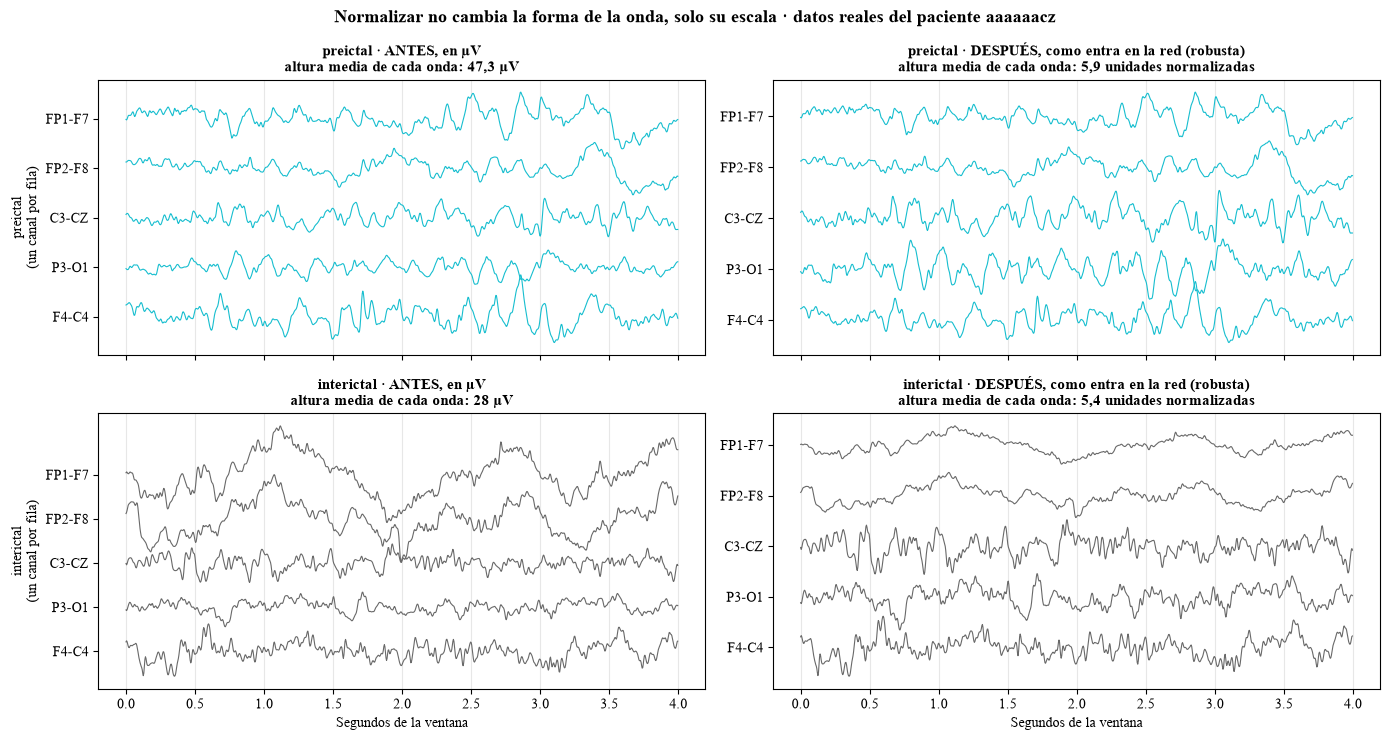

In [13]:
# Figura: una ⏳ preictal y una 💤 interictal del mismo paciente, antes y después de normalizar
entrena = indice_train.iloc[posiciones_entrena]
paciente_ejemplo = sorted(entrena.groupby('patient').clase.nunique().loc[lambda s: s == 2].index)[0]
ejemplo = {clase: int(rng.choice(entrena.index[(entrena.patient == paciente_ejemplo) & (entrena.clase == clase)]))
           for clase in ['preictal', 'interictal']}
canales = [CANALES_TCP.index(c) for c in CANALES_FIGURAS]
t = np.arange(MUESTRAS) / (MUESTRAS / VENTANA_S)

with plt.rc_context(ESTILO_TIMES):
    fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharex=True)
    for fila, (clase, i) in enumerate(ejemplo.items()):
        cruda = np.asarray(matriz_train[i], dtype=np.float32)[canales]
        normalizada = np.clip(NORMALIZACIONES[NORMALIZACION](cruda), -RECORTE, RECORTE)
        for col, (datos, unidad) in enumerate([(cruda, 'µV'), (normalizada, 'unidades normalizadas')]):
            ax = axes[fila, col]
            separacion = 4 * np.median(np.percentile(datos, 75, axis=-1) - np.percentile(datos, 25, axis=-1)) + 1e-6
            for k in range(len(canales)):
                ax.plot(t, datos[k] - k * separacion, color=COLORES_PERIODO[clase] if clase == 'preictal' else 'dimgray', lw=0.8)
            ax.set_yticks([-k * separacion for k in range(len(canales))], CANALES_FIGURAS)
            rango = np.ptp(datos, axis=-1).mean()
            ax.set_title(f'{clase} · {"ANTES, en µV" if col == 0 else f"DESPUÉS, como entra en la red ({NORMALIZACION})"}\n'
                         f'altura media de cada onda: {numero_legible(round(rango, 1))} {unidad}', fontsize=11, fontweight='bold')
            ax.grid(axis='x', alpha=0.3)
        axes[fila, 0].set_ylabel(f'{clase}\n(un canal por fila)')
    for ax in axes[1]:
        ax.set_xlabel('Segundos de la ventana')
    fig.suptitle(f'Normalizar no cambia la forma de la onda, solo su escala · datos reales del paciente {paciente_ejemplo}',
                 fontsize=13, fontweight='bold')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'normalizacion_ejemplo.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Ahora con **datos reales**. Arriba, una ventana ⏳ preictal; abajo, una 💤 interictal del **mismo paciente**. Cada línea es un canal (uno de cada cadena del montaje, F01.03). A la izquierda, en µV; a la derecha, tal como entran en la red.

✅ **Qué deberías ver:** la **forma** de cada onda es la misma a los dos lados; solo cambia la escala (el número del título), que a la derecha es parecida en todas.

## 7. Reflejar: ejemplos nuevos y creíbles (aumento de datos)

> 🎯 **Qué hacemos:** al estudiar, reflejar al azar la mitad de las ventanas de izquierda a derecha.
>
> 🤔 **Por qué:** hay pocas crisis. Una crisis que se prepara en el lado izquierdo podría prepararse igual en el derecho: reflejando, la red ve más variedad y no aprende "el lado" en vez del patrón. Es lo que hace Tang et al. 2021 con TUSZ (síntesis del estado del arte). **Solo al estudiar**: los exámenes se hacen con la ventana tal cual.

![Reflejo de hemisferios](img/reflejo_hemisferios.png)

👀 **Qué enseña.** A la izquierda, la cabeza vista desde arriba con la cadena temporal izquierda en rojo. A la derecha, la ventana reflejada: esa señal pasa a los canales de la derecha. La regla (cuadro de la derecha): cada electrodo cambia por su espejo (impar = izquierda ↔ par = derecha). Los canales de la cadena central cruzan la cabeza y, al reflejarlos, quedan **al revés**: se les cambia el signo.

In [14]:
cadena_de = {f'{a}-{c}': cadena for cadena, pares in CADENAS_TCP.items() for a, c in pares}
tabla_espejo = pd.DataFrame({'cadena': [cadena_de[c] for c in CANALES_TCP], 'canal': CANALES_TCP,
                             'en la ventana reflejada lleva la señal de': [('−' if s < 0 else '') + CANALES_TCP[o] for o, s in zip(ORIGEN_ESPEJO, SIGNO_ESPEJO)]})
display(con_separadores(tabla_espejo.set_index(['cadena', 'canal'])))

prueba = torch.randn(8, N_CANALES, 16)
dos_veces = reflejar_hemisferios(reflejar_hemisferios(prueba, 1.0), 1.0)
reflejo_ok = torch.equal(prueba, dos_veces)
print(f'{"✅" if reflejo_ok else "🔴"} Reflejar dos veces deja la ventana como estaba (el espejo del espejo es el original)')
print(f'{"✅" if sorted(ORIGEN_ESPEJO) == list(range(N_CANALES)) else "🔴"} Cada canal recibe la señal de un canal distinto (ninguno se pierde ni se repite)')
print(f'Canales que cambian de signo (cadena central): {int((SIGNO_ESPEJO < 0).sum())}')
assert reflejo_ok

✅ Reflejar dos veces deja la ventana como estaba (el espejo del espejo es el original)
✅ Cada canal recibe la señal de un canal distinto (ninguno se pierde ni se repite)
Canales que cambian de signo (cadena central): 6


👀 **Cómo leer la tabla.** Para cada canal (agrupados por cadena del montaje), de qué canal toma la señal en la ventana reflejada: las cadenas de la izquierda toman la de la derecha y al revés. El **−** marca los canales de la cadena central, que se invierten.

✅ **Qué deberías ver:** las dos comprobaciones con ✅: reflejar dos veces deja la ventana como estaba, y ningún canal se pierde ni se repite.

## 8. Servir lotes: Dataset y DataLoader

> 🎯 **Qué hacemos:** montar las dos piezas de PyTorch que entregarán las ventanas a la red, sacar un lote de prueba y medir la velocidad.
>
> 🤔 **Por qué:** es lo único que necesitará F03.02. Y si servir los datos fuera más lento que la red, la GPU se quedaría esperando.

![Dataset y DataLoader](img/dataset_y_dataloader.png)

👀 **Qué enseña.** El **Dataset** es el almacén: si le pides la ventana n.º 9, te la da con su respuesta. El **DataLoader** es el repartidor: coge 64, las prepara (misma escala, recorte y, al estudiar, reflejo) y se las da a la red. Para los exámenes no baraja ni refleja.

![Del índice al lote que entra en la red](img/del_indice_al_lote.png)

👀 **Qué enseña.** El camino completo de una ventana: arriba, lo que se hace **una vez** en este notebook (§3-§4); abajo, lo que pasa **en cada época** al estudiar (§6-§8).

In [15]:
# Un Dataset por vista, con las filas de su paquete (si la vista sale de dos particiones, como en la validación
# cruzada, se juntan sus dos Dataset con ConcatDataset)
def dataset_de_vista(vista):
    partes = []
    for split in sorted(set(vistas[vista].split)):
        _, indice_split = cargar_paquete(CONJUNTO, split)
        posiciones = np.flatnonzero(indice_split[f'en_{vista}'].to_numpy())
        partes.append(VentanasEEG(rutas_paquete(CONJUNTO, split)[0], posiciones, indice_split.etiqueta.to_numpy()[posiciones]))
    return partes[0] if len(partes) == 1 else ConcatDataset(partes)
datasets = {vista: dataset_de_vista(vista) for vista in vistas}

preparar_entrenar = PrepararLote(NORMALIZACION, RECORTE, REFLEJO)
preparar_medir = PrepararLote(NORMALIZACION, RECORTE, 0.0)
cargadores = {nombre: crear_cargador(ds, preparar_entrenar if nombre == 'entrenamiento' else preparar_medir,
                                     TAMANO_LOTE, barajar=nombre == 'entrenamiento', semilla=SEMILLA,
                                     n_trabajadores=N_TRABAJADORES, pin_memory=dispositivo.type == 'cuda')
              for nombre, ds in datasets.items()}

x, y = next(iter(cargadores['entrenamiento']))
lote = pd.DataFrame({'qué es': ['ventanas (x)', 'etiquetas (y)'], 'forma': [tuple(x.shape), tuple(y.shape)],
                     'tipo': [str(x.dtype), str(y.dtype)],
                     'contenido': [f'mediana {decimal(x.median(), 2)} · valores entre {decimal(x.min())} y {decimal(x.max())}',
                                   f'{int(y.sum())} ⏳ preictales y {int((1 - y).sum())} 💤 interictales']}).set_index('qué es')
display(Markdown('**Un lote de entrenamiento, tal como entra en la red**'))
display(lote)

**Un lote de entrenamiento, tal como entra en la red**

,forma,tipo,contenido
qué es,,,
ventanas (x),"(64, 22, 1024)",torch.float32,"mediana -0,00 · valores entre -20,0 y 20,0"
etiquetas (y),"(64,)",torch.float32,28 ⏳ preictales y 36 💤 interictales


👀 **Cómo leer la tabla.** Es **un lote real**, tal como lo recibirá la red:

- **x** (las ventanas): forma `(64, 22, 1024)` = 64 ventanas × 22 canales × 1.024 números, ya en la misma escala (valores alrededor de 0, sin pasar de ±20).
- **y** (las respuestas): 64 unos y ceros.

✅ **Qué deberías ver:** más o menos la mitad de ⏳ y la mitad de 💤 (el grupo de estudio está equilibrado y barajado).

In [16]:
# Velocidad: ventanas por segundo que sirve cada DataLoader (sin red: solo leer y preparar)
def medir(cargador, n_lotes):
    inicio, ventanas = time.time(), 0
    for k, (xb, yb) in enumerate(cargador):
        ventanas += len(yb)
        if k + 1 >= n_lotes:
            break
    return ventanas / (time.time() - inicio)

filas_velocidad = {}
for nombre, cargador in cargadores.items():
    por_segundo = medir(cargador, N_LOTES_VELOCIDAD)
    filas_velocidad[nombre] = {'ventanas': len(datasets[nombre]), 'lotes': len(cargador),
                               'ventanas por segundo': por_segundo, 'segundos por pasada (solo datos)': len(datasets[nombre]) / por_segundo}
tabla_velocidad = pd.DataFrame(filas_velocidad).T
tabla_velocidad.index.name = 'vista'
display(con_separadores(tabla_velocidad, decimales=0))
segundos_epoca = float(tabla_velocidad.loc['entrenamiento', 'segundos por pasada (solo datos)'])

,ventanas,lotes,ventanas por segundo,segundos por pasada (solo datos)
vista,,,,
entrenamiento,36.834,576,1.301,28
validacion,58.471,914,1.338,44
evaluacion,48.586,760,1.537,32
control_posicion,14.387,225,1.549,9
control_misma_sesion,26.148,409,1.616,16
control_misma_sesion_estricta,14.424,226,1.560,9


👀 **Cómo leer la tabla.** Para cada grupo: cuántas ventanas tiene, en cuántos **lotes** se reparten, cuántas ventanas por segundo se pueden servir (leer + preparar, todavía **sin red**) y cuántos segundos tardaría una vuelta entera.

✅ **Qué deberías ver:** en *entrenamiento*, una vuelta (época) de pocos segundos o decenas de segundos. Si fueran minutos, la red esperaría a los datos y habría que subir `N_TRABAJADORES`.

## 9. El resultado → `vistas.csv` y `configuracion.json`

Se guarda el resumen de los grupos y la configuración (escala, recorte, reflejo, tamaño de lote, semilla...) para que F03.02 la lea y prepare los datos **exactamente igual**.

In [17]:
resumen_vistas.to_csv(RUTA_RESULTADOS / 'vistas.csv')
mostrar_fichero(RUTA_RESULTADOS / 'vistas.csv', 'una fila por vista: para qué se usa, de qué partición sale, pacientes, crisis, '
                'ventanas de cada clase y desbalance')

config = {
    'conjunto': CONJUNTO, 'modo_prueba': modo_prueba, 'normalizacion': NORMALIZACION, 'recorte': RECORTE,
    'reflejo': REFLEJO, 'tamano_lote': TAMANO_LOTE, 'n_trabajadores': N_TRABAJADORES, 'splits_control': SPLITS_CONTROL,
    'semilla': SEMILLA, 'ventana_s': VENTANA_S, 'muestras_por_ventana': MUESTRAS, 'canales': N_CANALES,
    'vistas': list(vistas), 'paquetes': {s: str(rutas_paquete(CONJUNTO, s)[0]) for s in indices},
    'dispositivo': ficha_dispositivo['dispositivo'], 'versiones': versiones_usadas,
    'fecha': time.strftime('%Y-%m-%d %H:%M'),
}
(RUTA_RESULTADOS / 'configuracion.json').write_text(json.dumps(config, ensure_ascii=False, indent=4), encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'configuracion.json', 'la configuración de los datos de la red, para que F03.02 y los siguientes la lean y la repitan igual')

gb_total = float(tabla_paquetes.GB.sum())
mostrar_destacado(f'Los datos de la red para el conjunto {CONJUNTO}',
                  f'<b>{len(vistas)} vistas</b> en <b>{len(indices)} paquetes</b> ({numero_legible(round(gb_total, 1))} GB). '
                  f'La red entrenará con <b>{numero_legible(len(vistas["entrenamiento"]))} ventanas</b> de '
                  f'{numero_legible(vistas["entrenamiento"].patient.nunique())} pacientes, en lotes de {TAMANO_LOTE}, '
                  f'normalizadas ({NORMALIZACION}, recorte ±{RECORTE}) y con reflejo al {numero_legible(100 * REFLEJO)} %.',
                  tabla_con_iconos(resumen_vistas.drop(columns='para qué')))

💾 **Guardado `vistas.csv`** · 778 B · 6 filas × 9 columnas  
*Qué guarda:* una fila por vista: para qué se usa, de qué partición sale, pacientes, crisis, ventanas de cada clase y desbalance. *Abajo:* las 5 primeras filas.

,vista,partición,para qué,pacientes,crisis,⏳ preictal,💤 interictal,💤 por cada ⏳,ventanas
0,entrenamiento,train,Entrenar la red (equilibrado: mitad y mitad en...,84,247,18417,18417,1.00,36834
1,validacion,dev,"Elegir época, hiperparámetros y umbral (desbal...",36,133,11190,47281,4.23,58471
2,evaluacion,eval,Nota final (desbalance real). Solo se mira al ...,30,98,8375,40211,4.80,48586
3,control_posicion,eval,Control H4: 💤 de los mismos minutos del ficher...,27,98,8375,6012,0.72,14387
4,control_misma_sesion,eval,Control H5: 💤 de ficheros sin crisis de la mis...,28,98,8375,17773,2.12,26148


💾 **Guardado `configuracion.json`** · 1,2 KB · 17 claves  
*Qué guarda:* la configuración de los datos de la red, para que F03.02 y los siguientes la lean y la repitan igual. *Abajo:* todas las claves (son pocas).

,valor
clave,
conjunto,general
modo_prueba,false
normalizacion,robusta
recorte,20
reflejo,0.5
tamano_lote,64
n_trabajadores,0
splits_control,"[""eval""]"
semilla,42


,partición,pacientes,crisis,⏳ preictal,💤 interictal,💤 por cada ⏳,ventanas
vista,,,,,,,
entrenamiento,train,84,247,18417,18417,1.0,36834
validacion,dev,36,133,11190,47281,4.23,58471
🟢 evaluacion,eval,30,98,8375,40211,4.8,48586
control_posicion,eval,27,98,8375,6012,0.72,14387
control_misma_sesion,eval,28,98,8375,17773,2.12,26148
control_misma_sesion_estricta,eval,27,98,8375,6049,0.72,14424


## 10. Resumen → `summary.txt`

In [18]:
datos = [
    f'Datos de la red: {config["fecha"]} · conjunto {CONJUNTO}' + ('  ·  MODO PRUEBA (Fase 2 incompleta)' if modo_prueba else ''),
    f'Ventanas de {VENTANA_S} s: {N_CANALES} canales × {numero_legible(MUESTRAS)} muestras · lotes de {TAMANO_LOTE} · semilla {SEMILLA}',
    f'Normalización por ventana y canal: {NORMALIZACION}, recorte ±{RECORTE} · reflejo de hemisferios al entrenar: {numero_legible(100 * REFLEJO)} %',
    f'Paquetes: {len(indices)} ({numero_legible(round(gb_total, 1))} GB) · comprobación: {"OK" if paquetes_ok else "FALLA"}',
    f'Dispositivo: {ficha_dispositivo["dispositivo"]} ({ficha_dispositivo["nombre"]})',
    f'Velocidad del DataLoader de entrenamiento: {numero_legible(round(float(tabla_velocidad.loc["entrenamiento", "ventanas por segundo"])))} ventanas/s '
    f'(~{numero_legible(round(segundos_epoca))} s por época solo en datos)',
]
tablas_resumen = {'Vistas': tabla_con_iconos(resumen_vistas.drop(columns='para qué')),
                  'Paquetes': tabla_con_iconos(tabla_paquetes.round(2)),
                  'Comprobación de los paquetes': tabla_con_iconos(tabla_comprobacion.round(0)),
                  'Normalización (muestra de entrenamiento)': tabla_normalizacion.round(3),
                  'Velocidad del DataLoader': tabla_velocidad.round(0)}
texto = ('=== F03.01 · Datos de la red ===\n' + '\n'.join(datos) + '\n\n'
         + '\n\n'.join(f'--- {titulo} ---\n{tabla.to_string()}' for titulo, tabla in tablas_resumen.items()) + '\n')
(RUTA_RESULTADOS / 'summary.txt').write_text(texto, encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'summary.txt', 'el resumen de los datos de la red en texto, para consultarlo sin abrir el notebook')

💾 **Guardado `summary.txt`** · 4 KB · 51 líneas  
*Qué guarda:* el resumen de los datos de la red en texto, para consultarlo sin abrir el notebook. *Abajo:* las 5 primeras líneas con texto.

,texto
línea,
1,=== F03.01 · Datos de la red ===
2,Datos de la red: 2026-11-03 16:51 · conjunto general
3,Ventanas de 4 s: 22 canales × 1.024 muestras · lotes de 64 · semilla 42
4,"Normalización por ventana y canal: robusta, recorte ±20 · reflejo de hemisferios al entrenar: 50 %"
5,"Paquetes: 3 (6,5 GB) · comprobación: OK"


## 11. Conclusiones

Se escriben solas a partir de los datos al ejecutar la celda.

In [19]:
entr, val = vistas['entrenamiento'], vistas.get('validacion', vistas.get('validacion_cruzada'))
evaluacion = vistas['evaluacion']
controles_listos = [v for v in vistas if v.startswith('control_')]
fuera_recorte = float(tabla_normalizacion.loc['5 · % de ventanas con algún valor recortado', NORMALIZACION])
otra = [n for n in NORMALIZACIONES if n != NORMALIZACION][0]
lento = segundos_epoca > 120
conclusiones = [
    f'**1. Cada vista tiene sus ventanas y ningún paciente se cuela.** La red entrenará con {numero_legible(len(entr))} ventanas '
    f'({numero_legible(entr.patient.nunique())} pacientes, {decimal(100 * (entr.clase == "preictal").mean(), 0)} % ⏳ preictal). '
    f'{"Validación" if "validacion" in vistas else "Validación cruzada"} y evaluación conservan el desbalance real '
    f'({decimal((val.clase == "interictal").sum() / max((val.clase == "preictal").sum(), 1))} y '
    f'{decimal((evaluacion.clase == "interictal").sum() / max((evaluacion.clase == "preictal").sum(), 1))} 💤 por cada ⏳): sus métricas serán honestas.',
    (f'**2. Los controles de F02.05 están listos** ({", ".join(controles_listos)}): la nota final se podrá dar también sin las pistas tramposas.'
     if controles_listos else f'**2. 🟡 No hay controles de F02.05 para `{CONJUNTO}`** (F02.05 revisó `{config_05["conjunto"]}`): para contrastar su nota final, ejecutar F02.05 con este conjunto o dejarlo como limitación.'),
    f'**3. Los paquetes son fieles a la señal.** {len(indices)} paquetes, {numero_legible(round(gb_total, 1))} GB; '
    f'{int(tabla_comprobacion["ventanas comprobadas"].sum())} ventanas comparadas con la original, todas idénticas, sin NaN y por debajo del umbral de rechazo.'
    + ('' if amplitud_ok else ' 🔴 Ojo: alguna ventana pasa del umbral de rechazo de F02.03.'),
    f'**4. Escala: normalización {NORMALIZACION}, con recorte ±{RECORTE}.** Deja cada canal centrado en '
    f'{decimal(tabla_normalizacion.loc["1 · centro de cada canal (ideal: 0)", NORMALIZACION], 2)} y con escala '
    f'{decimal(tabla_normalizacion.loc["2 · ancho de cada canal (ideal: 1)", NORMALIZACION], 2)}; el recorte toca el '
    f'{decimal(fuera_recorte)} % de las ventanas (las que tienen artefactos)'
    + (f', así que no cambia casi nada del EEG normal.' if fuera_recorte < 5 else
       f'. 🟡 Es bastante: valorar un RECORTE algo mayor o la normalización {otra} en la Fase 3.'),
    f'**5. Velocidad.** El DataLoader de entrenamiento sirve {numero_legible(round(float(tabla_velocidad.loc["entrenamiento", "ventanas por segundo"])))} ventanas/s: '
    f'~{numero_legible(round(segundos_epoca))} s por época solo en datos'
    + ('. 🟡 Es lento: probar N_TRABAJADORES = 2-4 en F03.02.' if lento else ', de sobra para no frenar a la red.'),
    f'**6. Dispositivo: {ficha_dispositivo["dispositivo"]}.** ' + (ficha_dispositivo['aviso'] or 'La red se entrenará en la GPU (tarjeta gráfica).'),
]
display(Markdown('\n\n'.join(conclusiones)))

**1. Cada vista tiene sus ventanas y ningún paciente se cuela.** La red entrenará con 36.834 ventanas (84 pacientes, 50 % ⏳ preictal). Validación y evaluación conservan el desbalance real (4,2 y 4,8 💤 por cada ⏳): sus métricas serán honestas.

**2. Los controles de F02.05 están listos** (control_posicion, control_misma_sesion, control_misma_sesion_estricta): la nota final se podrá dar también sin las pistas tramposas.

**3. Los paquetes son fieles a la señal.** 3 paquetes, 6,5 GB; 900 ventanas comparadas con la original, todas idénticas, sin NaN y por debajo del umbral de rechazo.

**4. Escala: normalización robusta, con recorte ±20.** Deja cada canal centrado en 0,00 y con escala 1,00; el recorte toca el 1,9 % de las ventanas (las que tienen artefactos), así que no cambia casi nada del EEG normal.

**5. Velocidad.** El DataLoader de entrenamiento sirve 1.301 ventanas/s: ~28 s por época solo en datos, de sobra para no frenar a la red.

**6. Dispositivo: cuda (GPU NVIDIA).** La red se entrenará en la GPU (tarjeta gráfica).

## 12. Archivos generados y siguiente paso

En `outputs/fase_03/01_datos_red/`:

- `paquetes/<CONJUNTO>/<split>.npy`: la señal de las ventanas de cada partición, juntas (ventanas × 22 canales × 1.024 números, en µV, sin normalizar).
- `paquetes/<CONJUNTO>/<split>_indice.csv`: una fila por ventana del paquete, en el mismo orden, con a qué vistas pertenece (`en_...`).
- `vistas.csv`: qué es cada vista y cuántas ventanas, pacientes y crisis tiene.
- `configuracion.json`: normalización, recorte, reflejo, tamaño de lote, semilla, versiones y fecha. Los notebooks siguientes la leen.
- `summary.txt`: las tablas de este notebook, en texto.
- `figuras/normalizacion_ejemplo.png`.

> ⚠️ `paquetes/` ocupa varios GB: **no subir a GitHub** (añadir `outputs/**/paquetes/` al `.gitignore`).

**Siguiente paso → F03.02:** **declarar la red** y entrenarla. Solo tendrá que leer `configuracion.json`, abrir los paquetes y pedir lotes al DataLoader.